# Análisis Exploratorio de Datos (EDA)
Este notebook contiene la exploración inicial del dataset PaySim1.

In [1]:
# CELDA 1: Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de gráficas
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
%matplotlib inline

In [2]:
# CELDA 2: Cargar el dataset
df = pd.read_csv('../data/raw/PS_20174392719_1491204439457_log.csv')

print('Dimensiones:', df.shape)         # filas x columnas
print('\nPrimeras filas:')
df.head()

Dimensiones: (6362620, 11)

Primeras filas:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
# CELDA 3: Información general
print('=== TIPOS DE DATOS ===')
print(df.dtypes)
print('\n=== VALORES NULOS ===')
print(df.isnull().sum())
print('\n=== ESTADÍSTICAS ===')
df.describe()

=== TIPOS DE DATOS ===
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

=== VALORES NULOS ===


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

=== ESTADÍSTICAS ===


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


Distribución de clases:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Porcentaje de fraude: 0.1291%


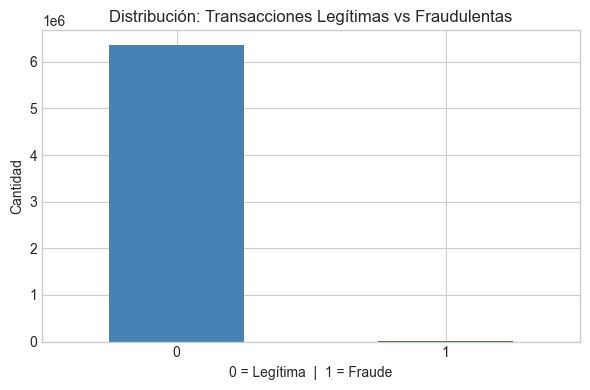

In [4]:
# CELDA 4: Distribución de la variable objetivo
fraude = df['isFraud'].value_counts()
print('Distribución de clases:')
print(fraude)
print(f'\nPorcentaje de fraude: {fraude[1]/len(df)*100:.4f}%')

# Gráfica de barras
plt.figure(figsize=(6,4))
fraude.plot(kind='bar', color=['steelblue','crimson'])
plt.title('Distribución: Transacciones Legítimas vs Fraudulentas')
plt.xlabel('0 = Legítima  |  1 = Fraude')
plt.ylabel('Cantidad')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../notebooks/fig_distribucion_clases.png', dpi=150)
plt.show()

          N_fraudes  N_total  Pct_fraude
type                                    
TRANSFER       4097   532909    0.768799
CASH_OUT       4116  2237500    0.183955
CASH_IN           0  1399284    0.000000
DEBIT             0    41432    0.000000
PAYMENT           0  2151495    0.000000


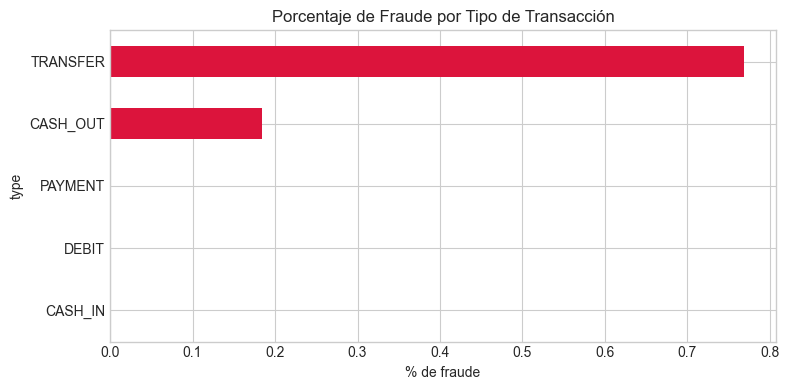

In [5]:
# CELDA 5: ¿En qué tipos de transacción ocurre el fraude?
fraude_tipo = df.groupby('type')['isFraud'].agg(['sum','count'])
fraude_tipo['porcentaje'] = fraude_tipo['sum'] / fraude_tipo['count'] * 100
fraude_tipo.columns = ['N_fraudes', 'N_total', 'Pct_fraude']
print(fraude_tipo.sort_values('Pct_fraude', ascending=False))

# Gráfica
plt.figure(figsize=(8,4))
fraude_tipo['Pct_fraude'].sort_values().plot(kind='barh', color='crimson')
plt.title('Porcentaje de Fraude por Tipo de Transacción')
plt.xlabel('% de fraude')
plt.tight_layout()
plt.savefig('../notebooks/fig_fraude_por_tipo.png', dpi=150)
plt.show()
# HALLAZGO ESPERADO: El fraude solo ocurre en TRANSFER y CASH_OUT

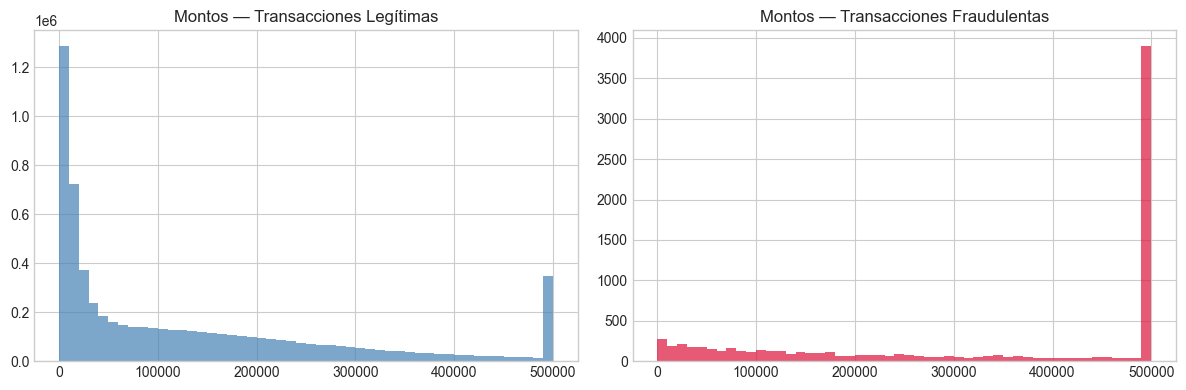

In [6]:
# CELDA 6: Distribución del monto en transacciones fraudulentas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df[df['isFraud']==0]['amount'].clip(upper=500000).hist(
    bins=50, ax=axes[0], color='steelblue', alpha=0.7)
axes[0].set_title('Montos — Transacciones Legítimas')

df[df['isFraud']==1]['amount'].clip(upper=500000).hist(
    bins=50, ax=axes[1], color='crimson', alpha=0.7)
axes[1].set_title('Montos — Transacciones Fraudulentas')

plt.tight_layout()
plt.savefig('../notebooks/fig_distribucion_montos.png', dpi=150)
plt.show()

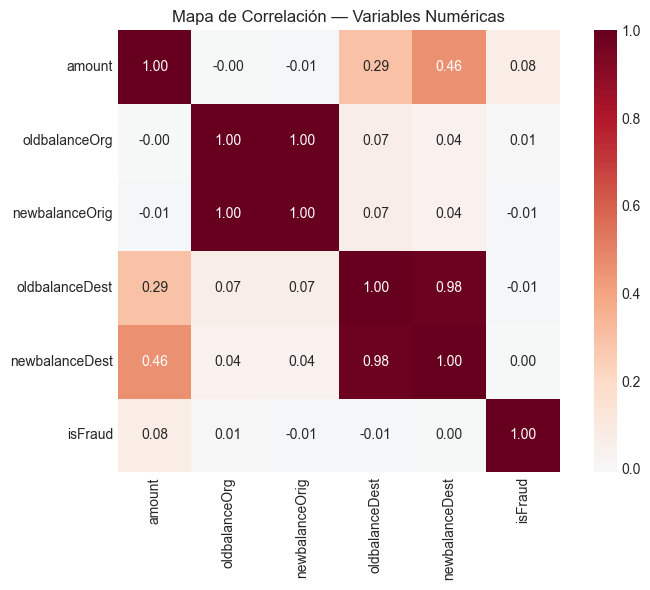

In [7]:
# CELDA 7: Mapa de correlación de variables numéricas
numericas = ['amount','oldbalanceOrg','newbalanceOrig',
             'oldbalanceDest','newbalanceDest','isFraud']
corr = df[numericas].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True)
plt.title('Mapa de Correlación — Variables Numéricas')
plt.tight_layout()
plt.savefig('../notebooks/fig_correlacion.png', dpi=150)
plt.show()